In [5]:
import pandas as pd
fruit = pd.read_csv('fruit-prices-2023.csv')
veg = pd.read_csv('vegetable-prices-2023.csv')

In [6]:
fruit.head(10)
# I'm noticing that there are four types of Apples, and they could be categorized better.
# I'd prefer if they had no comma, and instead there were a column for the types, such as 'applesauce', 'whole', or 'frozen concentrate'.
# Thankfully, there are no duplicates here, but the standardization for the 'Fruit' column isn't how I'd like it to be.

,Fruit,Form,AverageRetailPrice,AverageRetailPriceUnitOfMeasure,PreparationYieldFactor,SizeOfACupEquivalent,CupEquivalentUnitOfMeasure,AveragePricePerCupEquivalent
0,Apples,Fresh,1.860931,per pound,0.90,0.2425,pounds,0.501435
1,"Apples, applesauce",Canned,1.208099,per pound,1.00,0.5401,pounds,0.652534
2,"Apples, ready to drink",Juice,0.951115,per pint (16 fluid ounces ready to drink),1.00,0.5000,pints,0.475558
3,"Apples, frozen concentrate",Juice,2.668334,per pint (16 fluid ounces concentrate),4.00,0.5000,pints,0.333542
4,Apricots,Fresh,3.803732,per pound,0.93,0.3638,pounds,1.487802
5,"Apricots, in juice",Canned,2.107757,per pound,1.00,0.5401,pounds,1.138468
6,"Apricots, in syrup or water",Canned,2.556248,per pound,0.65,0.4409,pounds,1.734019
7,Apricots,Dried,8.634284,per pound,1.00,0.1433,pounds,1.237297
8,Bananas,Fresh,0.609595,per pound,0.64,0.3307,pounds,0.314983
9,"Berries, mixed",Frozen,4.448419,per pound,1.00,0.3307,pounds,1.471063


In [7]:
veg.head(20)

,Vegetable,Form,AverageRetailPrice,AverageRetailPriceUnitOfMeasure,PreparationYieldFactor,SizeOfACupEquivalent,CupEquivalentUnitOfMeasure,AveragePricePerCupEquivalent
0,Acorn squash,Fresh,1.241439,per pound,0.4586,0.4519,pounds,1.223533
1,Artichoke,Fresh,2.506856,per pound,0.3750,0.3858,pounds,2.080461
2,Artichoke,Canned,3.505101,per pound,0.6500,0.3858,pounds,2.579113
3,Asparagus,Fresh,3.212453,per pound,0.4938,0.3968,pounds,2.581436
4,Asparagus,Canned,3.676296,per pound,0.6500,0.3968,pounds,2.244419
5,Asparagus,Frozen,6.780905,per pound,1.0335,0.3968,pounds,2.603590
6,Avocados,Fresh,2.262403,per pound,0.7408,0.3197,pounds,0.976334
7,Beets,Canned,1.257920,per pound,0.6500,0.3748,pounds,0.725309
8,Black beans,Canned,1.306313,per pound,0.6500,0.3858,pounds,0.775365
9,Black beans,Dried,1.658510,per pound,2.4692,0.3858,pounds,0.259142


In [8]:
import seaborn as sns

import matplotlib.pyplot as plt

In [9]:
fruit_clean = fruit.copy()

# Separate Fruit into Name and Type
split_fruit = fruit_clean["Fruit"].str.split(",", n=1, expand=True)
fruit_clean["FruitName"] = split_fruit[0].str.strip()
fruit_clean["FruitType"] = split_fruit[1].str.strip().fillna("whole")

veg_clean = veg.copy()

# Separate Vegetable into Name and Type
split_veg = veg_clean["Vegetable"].str.split(",", n=1, expand=True)
veg_clean["VegetableName"] = split_veg[0].str.strip()
veg_clean["VegetableType"] = split_veg[1].str.strip().fillna("whole")
veg_clean.head(20)


,Vegetable,Form,AverageRetailPrice,AverageRetailPriceUnitOfMeasure,PreparationYieldFactor,SizeOfACupEquivalent,CupEquivalentUnitOfMeasure,AveragePricePerCupEquivalent,VegetableName,VegetableType
0,Acorn squash,Fresh,1.241439,per pound,0.4586,0.4519,pounds,1.223533,Acorn squash,whole
1,Artichoke,Fresh,2.506856,per pound,0.3750,0.3858,pounds,2.080461,Artichoke,whole
2,Artichoke,Canned,3.505101,per pound,0.6500,0.3858,pounds,2.579113,Artichoke,whole
3,Asparagus,Fresh,3.212453,per pound,0.4938,0.3968,pounds,2.581436,Asparagus,whole
4,Asparagus,Canned,3.676296,per pound,0.6500,0.3968,pounds,2.244419,Asparagus,whole
5,Asparagus,Frozen,6.780905,per pound,1.0335,0.3968,pounds,2.603590,Asparagus,whole
6,Avocados,Fresh,2.262403,per pound,0.7408,0.3197,pounds,0.976334,Avocados,whole
7,Beets,Canned,1.257920,per pound,0.6500,0.3748,pounds,0.725309,Beets,whole
8,Black beans,Canned,1.306313,per pound,0.6500,0.3858,pounds,0.775365,Black beans,whole
9,Black beans,Dried,1.658510,per pound,2.4692,0.3858,pounds,0.259142,Black beans,whole


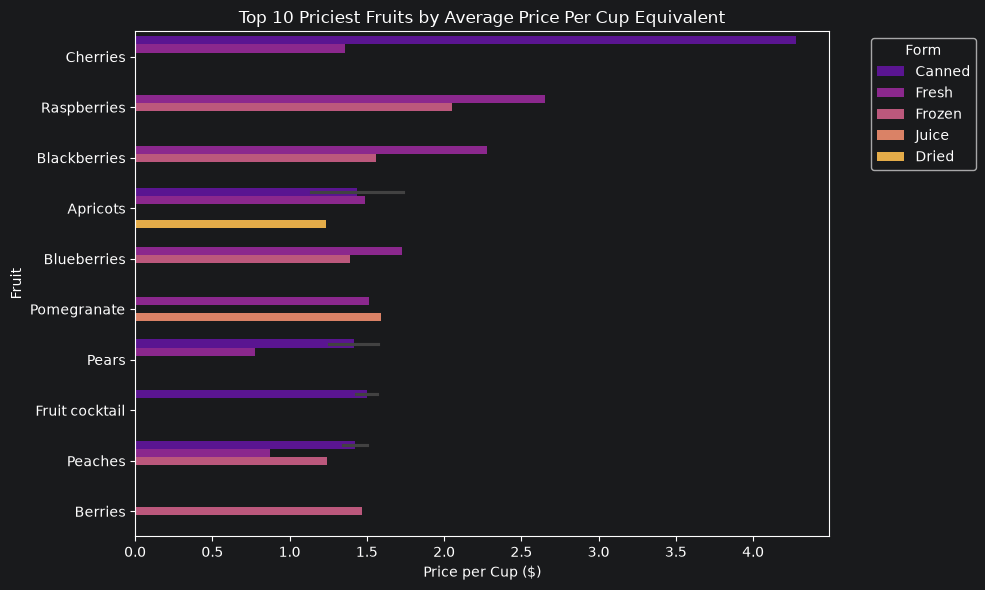

In [10]:
top_10_names = (
    fruit_clean.groupby("FruitName")["AveragePricePerCupEquivalent"]
    .max()
    .sort_values(ascending=False)
    .head(10)
    .index
)

top_fruit_prices = fruit_clean[fruit_clean["FruitName"].isin(top_10_names)] # AI helped here
top_fruit_prices = top_fruit_prices.sort_values("AveragePricePerCupEquivalent", ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=top_fruit_prices,
    x="AveragePricePerCupEquivalent",
    y="FruitName",
    hue="Form",
    dodge=True,
    palette="plasma"
)

plt.title("Top 10 Priciest Fruits by Average Price Per Cup Equivalent")
plt.xlabel("Price per Cup ($)")
plt.ylabel("Fruit")
plt.legend(title="Form", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()


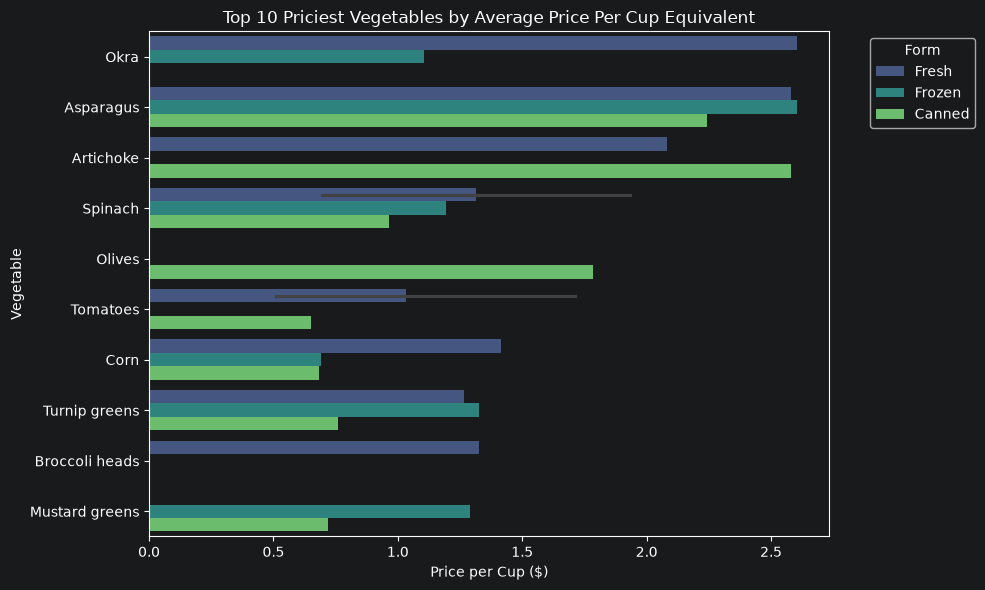

In [11]:
top_10_veg = (
    veg_clean.groupby("VegetableName")["AveragePricePerCupEquivalent"]
    .max()
    .sort_values(ascending=False)
    .head(10)
    .index
)

top_veg_prices = veg_clean[veg_clean[("VegetableName")].isin(top_10_veg)] # AI helped here
top_veg_prices = top_veg_prices.sort_values("AveragePricePerCupEquivalent", ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=top_veg_prices,
    x="AveragePricePerCupEquivalent",
    y="VegetableName",
    hue="Form",
    dodge=True,
    palette="viridis"
)

plt.title("Top 10 Priciest Vegetables by Average Price Per Cup Equivalent")
plt.xlabel("Price per Cup ($)")
plt.ylabel("Vegetable")
plt.legend(title="Form", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()


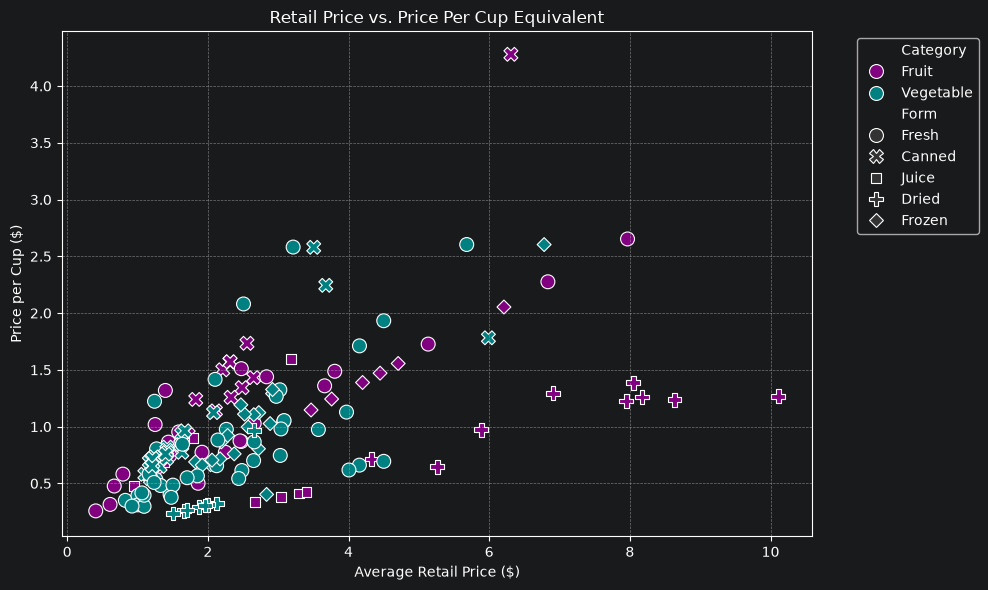

In [18]:
fruit_clean['Category'] = 'Fruit'
veg_clean['Category'] = 'Vegetable'

# Combine for scatterplot
combined = pd.concat([
    fruit_clean[['AverageRetailPrice', 'AveragePricePerCupEquivalent', 'Category', 'Form']],
    veg_clean[['AverageRetailPrice', 'AveragePricePerCupEquivalent', 'Category', 'Form']]
])

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=combined,
    x="AverageRetailPrice",
    y="AveragePricePerCupEquivalent",
    hue="Category",
    style="Form",
    s=100,
    palette={'Fruit': 'purple', 'Vegetable': 'teal'},

)

plt.title("Retail Price vs. Price Per Cup Equivalent")
plt.xlabel("Average Retail Price ($)")
plt.ylabel("Price per Cup ($)")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()